In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [5]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Elitism": root / "Elitism",
    "Crossover_95": root / "Crossover",
}
dataframes=[]
for source_name, folder in sources.items():
    if source_name == "Crossover_95":
        matching_folders = [
            path for path in folder.rglob("*")
            if path.is_dir() and path.name.endswith("95")
        ]
        for path in matching_folders:
            print(path.relative_to(root))
        csv_files = sorted({
            csv_file
            for matching_folder in matching_folders
            for csv_file in matching_folder.rglob("*.csv")
        })
    else:
        csv_files = sorted(folder.rglob("*.csv"))
    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

Crossover\Normal\Normal_acak_3_95
Crossover\Normal\Normal_Acak_4_95
Crossover\Normal\Normal_klaster_2_95
Crossover\Normal\Normal_labirin_2_95
Crossover\Small\Small_acak_3_95
Crossover\Small\Small_acak_4_95
Crossover\Small\Small_klaster_2_95
Crossover\Small\Small_labirin_2_95
Crossover\Tiny\Tiny_acak_3_95
Crossover\Tiny\Tiny_acak_4_95
Crossover\Tiny\Tiny_klaster_2_95
Crossover\Tiny\Tiny_labirin_2_95


In [7]:
df_All_Elitism_summary=(df_all.groupby(["grid_rows", "elitism_rate", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
))
display(df_All_Elitism_summary)

,grid_rows,elitism_rate,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.10,Cluster,2.507778,2.500000,2.600000,0.026932,90
1,10,0.10,Maze,3.337037,3.333333,3.500000,0.024705,90
2,10,0.10,Random,2.589484,2.416667,2.857143,0.159056,180
3,10,0.20,Cluster,2.514444,2.500000,2.600000,0.035351,90
4,10,0.20,Maze,3.337037,3.333333,3.500000,0.024705,90
5,10,0.20,Random,2.597884,2.416667,2.857143,0.157586,180
6,10,0.25,Cluster,2.503333,2.500000,2.600000,0.018051,90
7,10,0.25,Maze,3.337037,3.333333,3.500000,0.024705,90
8,10,0.25,Random,2.602712,2.416667,2.928571,0.162111,180
9,20,0.10,Cluster,4.789189,4.783784,4.918919,0.017284,90


In [9]:
table_random = (
    df_All_Elitism_summary[df_All_Elitism_summary["map_type"] == "Random"]
    .sort_values("elitism_rate")
)

display(table_random)
table_maze = (
    df_All_Elitism_summary[df_All_Elitism_summary["map_type"] == "Maze"]
    .sort_values("elitism_rate")
)

display(table_maze)
table_cluster = (
    df_All_Elitism_summary[df_All_Elitism_summary["map_type"] == "Cluster"]
    .sort_values("elitism_rate")
)

display(table_cluster)

,grid_rows,elitism_rate,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.10,Random,2.589484,2.416667,2.857143,0.159056,180
11,20,0.10,Random,6.245082,6.025000,6.487179,0.217790,180
20,40,0.10,Random,6.767778,6.700000,6.893750,0.046619,90
5,10,0.20,Random,2.597884,2.416667,2.857143,0.157586,180
23,40,0.20,Random,6.667225,6.512821,6.912500,0.106084,180
14,20,0.20,Random,6.247041,6.025000,6.512821,0.217133,180
8,10,0.25,Random,2.602712,2.416667,2.928571,0.162111,180
17,20,0.25,Random,6.249274,6.025000,6.512821,0.215945,180
26,40,0.25,Random,6.782778,6.706250,6.975000,0.051678,90


,grid_rows,elitism_rate,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.10,Maze,3.337037,3.333333,3.500000,0.024705,90
10,20,0.10,Maze,6.809972,6.794872,6.846154,0.014328,90
19,40,0.10,Maze,6.872644,6.834483,7.131034,0.041369,90
4,10,0.20,Maze,3.337037,3.333333,3.500000,0.024705,90
22,40,0.20,Maze,6.885824,6.834483,7.124138,0.045136,90
13,20,0.20,Maze,6.809402,6.794872,6.846154,0.015399,90
7,10,0.25,Maze,3.337037,3.333333,3.500000,0.024705,90
16,20,0.25,Maze,6.812251,6.794872,6.846154,0.018365,90
25,40,0.25,Maze,6.895019,6.834483,7.124138,0.050561,90


,grid_rows,elitism_rate,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.10,Cluster,2.507778,2.500000,2.600000,0.026932,90
9,20,0.10,Cluster,4.789189,4.783784,4.918919,0.017284,90
18,40,0.10,Cluster,5.476057,5.445161,5.709677,0.039670,90
3,10,0.20,Cluster,2.514444,2.500000,2.600000,0.035351,90
21,40,0.20,Cluster,5.484946,5.445161,5.651613,0.037771,90
12,20,0.20,Cluster,4.788589,4.783784,4.810811,0.010391,90
6,10,0.25,Cluster,2.503333,2.500000,2.600000,0.018051,90
15,20,0.25,Cluster,4.789489,4.783784,4.837838,0.012484,90
24,40,0.25,Cluster,5.491183,5.445161,5.600000,0.034523,90


In [ ]:
df_All_Elitism_summary["rank_mean_cost"] = (
    df_All_Elitism_summary
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_All = (
    df_All_Elitism_summary
    .groupby("elitism_rate", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_All)

,elitism_rate,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
1,0.20,1.777778,5.036932,0.072173,9
0,0.10,1.555556,5.043891,0.065306,9
2,0.25,2.666667,5.051453,0.065380,9


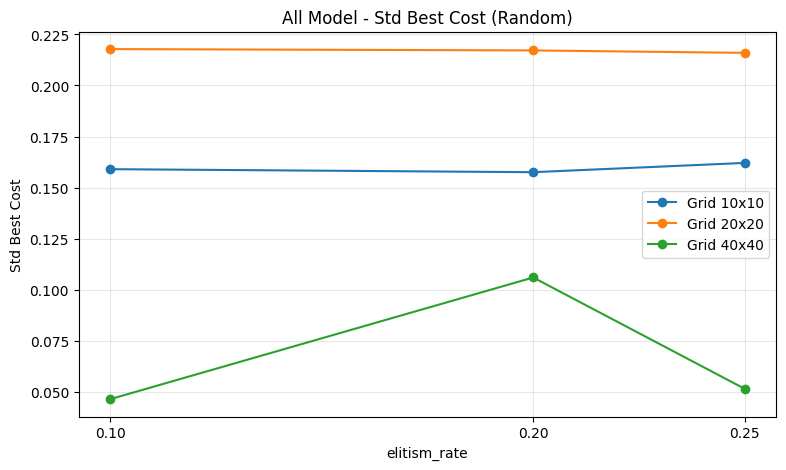

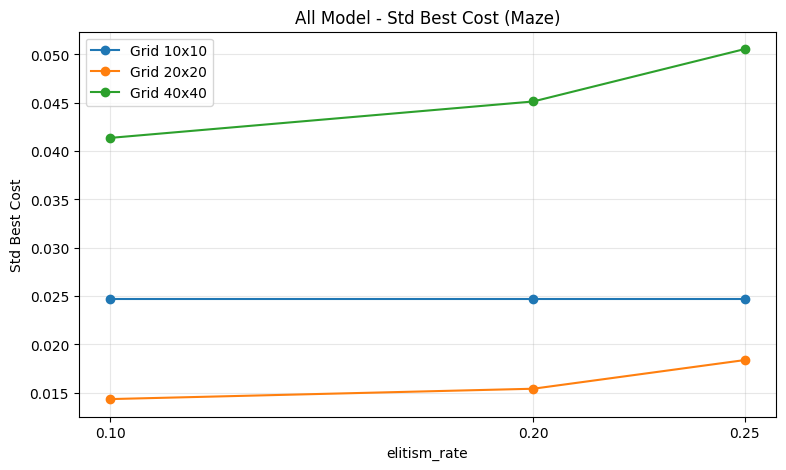

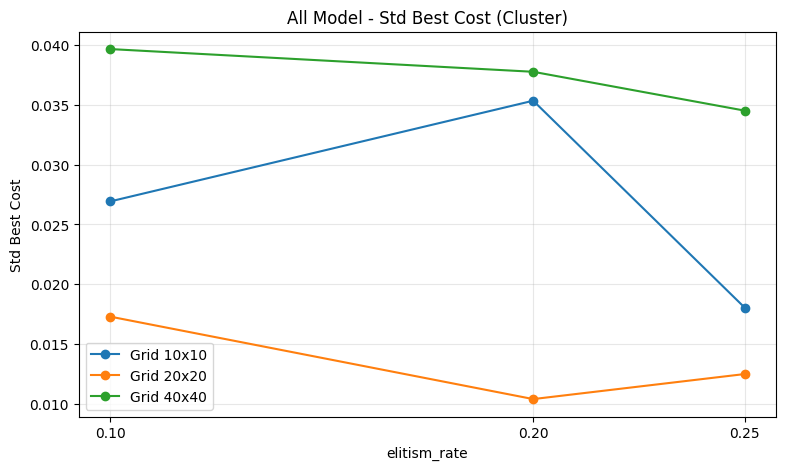

In [14]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = df_All_Elitism_summary[
        df_All_Elitism_summary["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("elitism_rate")
        )

        plt.plot(
            data_size["elitism_rate"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"All Model - Std Best Cost ({map_type})")
    plt.xlabel("elitism_rate")
    plt.ylabel("Std Best Cost")
    plt.xticks(sorted(data["elitism_rate"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [15]:
#rank std cost
df_All_Elitism_summary["rank_std_cost"] = (
    df_All_Elitism_summary
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_All_std = (
    df_All_Elitism_summary
    .groupby("elitism_rate", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values(["avg_rank_std", "avg_std_cost"])
)

print(avg_rank_All_std)


   elitism_rate  avg_rank_std  avg_std_cost  jumlah_kombinasi
0          0.10      1.888889      0.065306                 9
1          0.20      2.000000      0.072173                 9
2          0.25      2.111111      0.065380                 9


In [16]:
summary_All_time=(df_all.groupby(["grid_rows","elitism_rate", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_All_time)
avg_time_by_population_All = (
    summary_All_time.groupby("elitism_rate", as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values("avg_execTime")
)
display(avg_time_by_population_All)
summary_time_pivot = summary_All_time.pivot(
    index=["grid_rows", "elitism_rate"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_All_time.groupby(["map_type", "elitism_rate"], as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,elitism_rate,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.10,Cluster,47.555556,11,539,104.558796,90
1,10,0.10,Maze,40.911111,11,476,90.659338,90
2,10,0.10,Random,50.772222,10,590,96.675569,180
3,10,0.20,Cluster,41.477778,11,431,83.050036,90
4,10,0.20,Maze,39.733333,10,517,97.530727,90
5,10,0.20,Random,44.700000,9,487,86.977741,180
6,10,0.25,Cluster,43.888889,9,539,106.707144,90
7,10,0.25,Maze,38.833333,8,485,92.840597,90
8,10,0.25,Random,44.061111,8,458,78.104011,180
9,20,0.10,Cluster,147.877778,61,661,109.562442,90


,elitism_rate,avg_execTime,avg_std_time,jumlah_kombinasi
2,0.25,1500.135802,1461.144506,9
1,0.20,1594.145679,1485.601963,9
0,0.10,1892.024691,1675.511891,9


map_type                    Cluster         Maze       Random
grid_rows elitism_rate                                       
10        0.10            47.555556    40.911111    50.772222
          0.20            41.477778    39.733333    44.700000
          0.25            43.888889    38.833333    44.061111
20        0.10           147.877778   147.588889   156.294444
          0.20           143.622222   152.622222   140.688889
          0.25           144.722222   129.211111   138.494444
40        0.10          5718.833333  5541.266667  5177.122222
          0.20          4437.355556  4179.444444  5167.666667
          0.25          3895.655556  4150.222222  4916.133333

  map_type  elitism_rate  avg_execTime  avg_std_time  jumlah_kombinasi
2  Cluster          0.25   1361.422222   1290.611619                 3
1  Cluster          0.20   1540.818519   1427.974146                 3
0  Cluster          0.10   1971.422222   1923.482725                 3
5     Maze          0.25   1439.422222   1366.627672                 3
4     Maze          0.20   1457.266667   1362.032807                 3
3     Maze          0.10   1909.922222   1452.048992                 3
8   Random          0.25   1699.562963   1726.194226                 3
7   Random          0.20   1784.351852   1666.798936                 3
6   Random          0.10   1794.729630   1651.003957                 3


In [20]:
df_All_Elitism_summary_fitness=(df_all.groupby(["grid_rows", "elitism_rate", "map_type"], as_index=False).agg(
    mean_fitness=("best_fitness", "mean"),
    best_run=("best_fitness", "min"),
    worst_run=("best_fitness", "max"),
    std_fitness=("best_fitness", "std"),
    total_runs=("best_fitness", "count")
))
display(df_All_Elitism_summary_fitness)

,grid_rows,elitism_rate,map_type,mean_fitness,best_run,worst_run,std_fitness,total_runs
0,10,0.10,Cluster,0.285097,0.277778,0.285714,0.002137,90
1,10,0.10,Maze,0.230579,0.222222,0.230769,0.001267,90
2,10,0.10,Random,0.279136,0.259259,0.292683,0.012367,180
3,10,0.20,Cluster,0.284568,0.277778,0.285714,0.002806,90
4,10,0.20,Maze,0.230579,0.222222,0.230769,0.001267,90
5,10,0.20,Random,0.278473,0.259259,0.292683,0.012215,180
6,10,0.25,Cluster,0.285450,0.277778,0.285714,0.001433,90
7,10,0.25,Maze,0.230579,0.222222,0.230769,0.001267,90
8,10,0.25,Random,0.278128,0.254545,0.292683,0.012511,180
9,20,0.10,Cluster,0.172737,0.168950,0.172897,0.000508,90


In [22]:
df_All_Elitism_summary_fitness["rank_fitness_cost"] = (
    df_All_Elitism_summary_fitness
    .groupby(["grid_rows", "map_type"])["mean_fitness"]
    .rank(method="average", ascending=True)
)
avg_rank_All = (
    df_All_Elitism_summary_fitness
    .groupby("elitism_rate", as_index=False)
    .agg(
        avg_rank_mean=("rank_fitness_cost", "mean"),
        avg_mean_cost=("mean_fitness", "mean"),
        avg_std_cost=("std_fitness", "mean"),
        jumlah_kombinasi=("rank_fitness_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_All)

,elitism_rate,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
2,0.25,1.333333,0.182464,0.002496,9
0,0.10,2.444444,0.182659,0.002558,9
1,0.20,2.222222,0.182668,0.002710,9


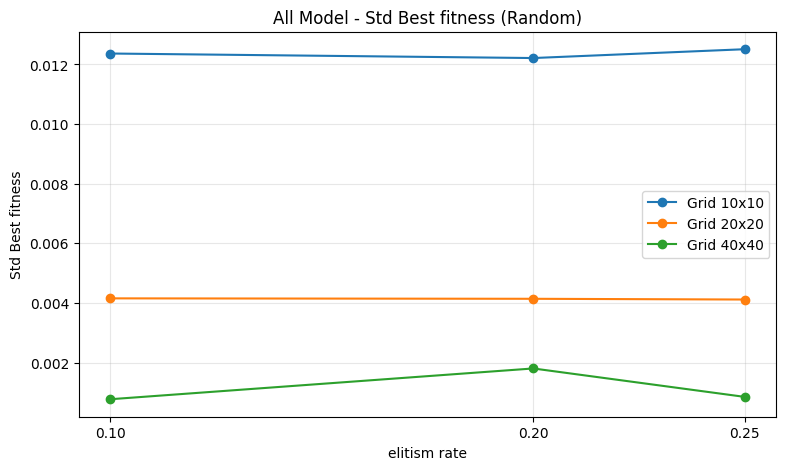

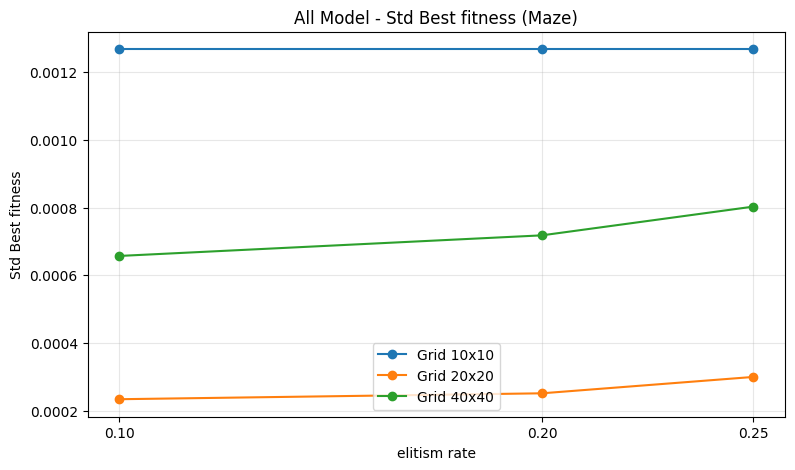

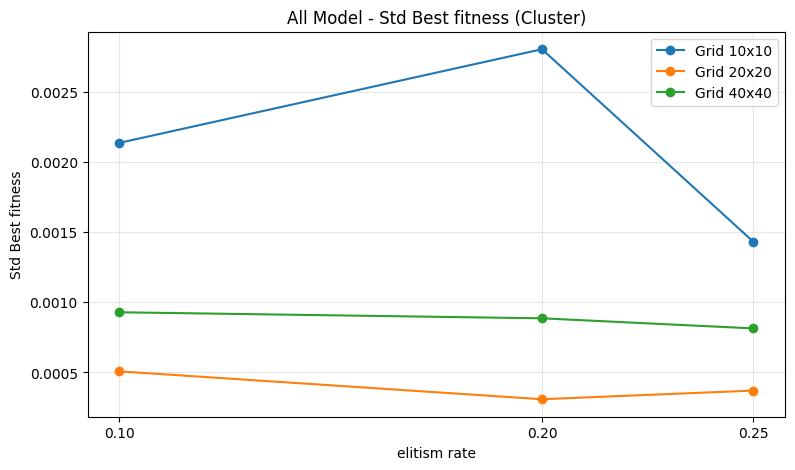

In [24]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = df_All_Elitism_summary_fitness[
        df_All_Elitism_summary_fitness["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("elitism_rate")
        )

        plt.plot(
            data_size["elitism_rate"],
            data_size["std_fitness"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"All Model - Std Best fitness ({map_type})")
    plt.xlabel("elitism rate")
    plt.ylabel("Std Best fitness")
    plt.xticks(sorted(data["elitism_rate"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()